# Green roof cooling in downtown Austin

Worked example for Kafy, Crews and Thompson (2024), *Sustainable Cities and Society* 116, 105893.

Steps:
1. Load the 30 m model table made by `download.py` and `prepare.py` (lidar urban form, Sentinel-2 indices, Landsat 8 daytime LST for 11 August 2023).
2. Compare neural networks with spatial block cross-validation.
3. Test which inputs the best network needs (leave one out).
4. Turn 4.2% of roof area green, hottest roofs first, and predict DLST again.

Real data, open tools. Numbers differ from the paper; see the README for why.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_predict

from greenroof import lidar, model, simulate

OUT, FIG = Path("outputs"), Path("figures")
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
df = pd.read_csv("data/features_30m.csv")
roofs = np.load("data/roofs_10m.npz")
INPUTS = ["BH_m", "BRI_m2", "BVD", "SVF", "SR_Wh_m2", "NDVI", "NDBI", "WBD_m"]
X, y = df[INPUTS], df["DLST_F"]
shape = (df.row.max() + 1, df.col.max() + 1)
groups = model.spatial_groups(df.row, df.col, 10)  # 300 m blocks
df[INPUTS + ["DLST_F"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BH_m,14400.0,8.19,12.43,0.00,0.00,6.53,10.41,154.79
BRI_m2,14400.0,177.19,235.34,0.00,0.00,76.00,268.00,900.00
BVD,14400.0,2.78,7.16,0.00,0.00,0.72,2.60,154.79
SVF,14400.0,0.71,0.10,0.28,0.66,0.72,0.77,1.00
SR_Wh_m2,14400.0,5733.19,713.68,1217.18,5436.53,5828.48,6205.01,6865.10
NDVI,14400.0,0.27,0.20,-0.04,0.10,0.24,0.41,0.86
NDBI,14400.0,0.01,0.11,-0.50,-0.05,0.02,0.08,0.49
WBD_m,14400.0,74.48,60.45,0.00,29.63,58.88,103.28,396.32
DLST_F,14400.0,120.86,6.15,93.38,117.90,122.00,125.07,137.60


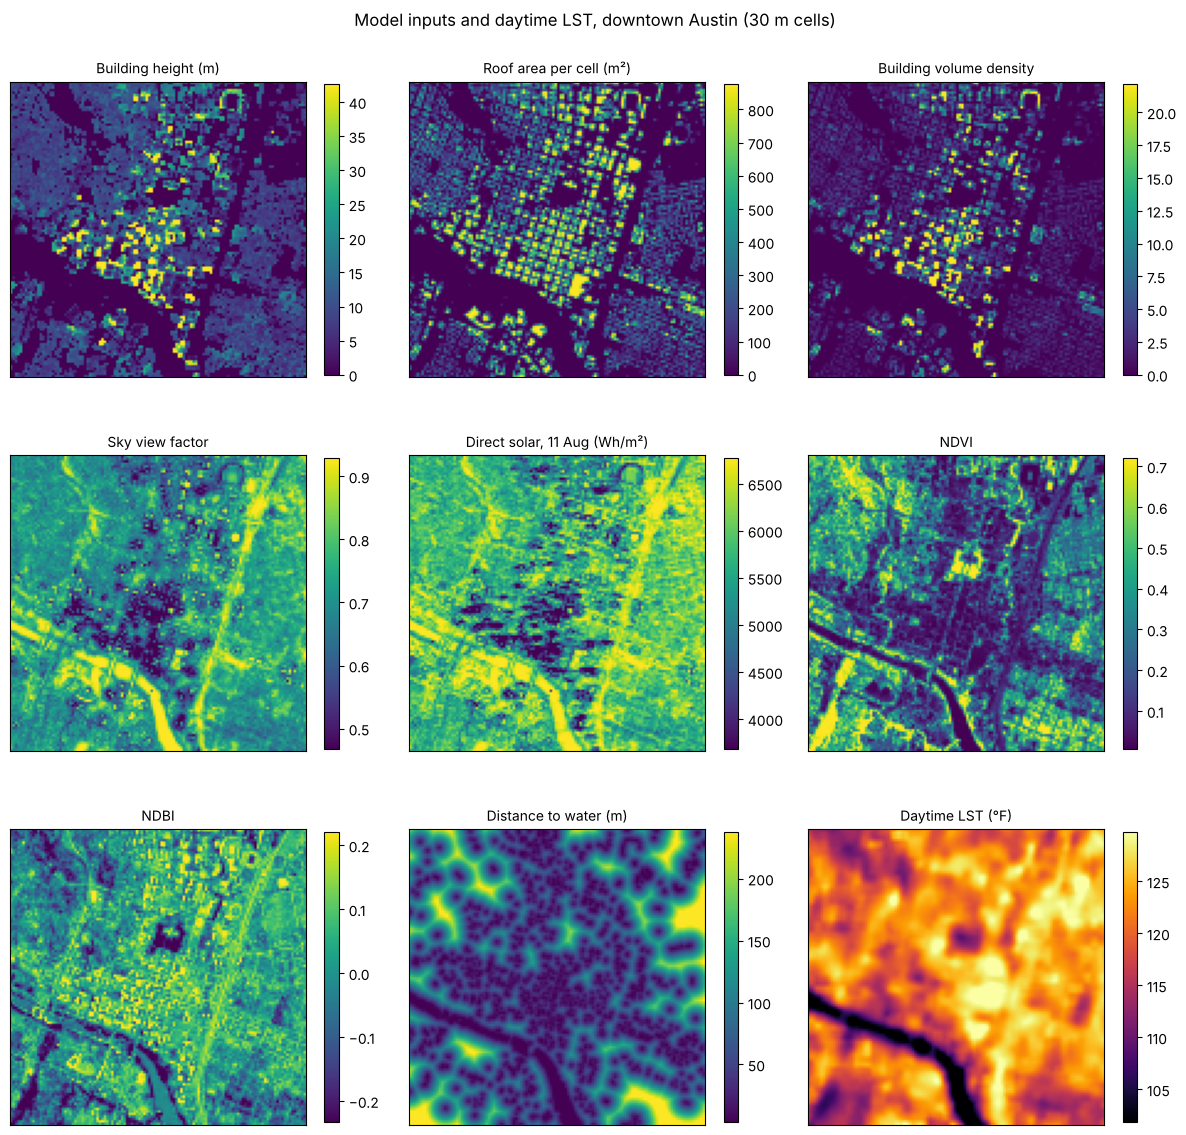

In [2]:
labels = {"BH_m": "Building height (m)", "BRI_m2": "Roof area per cell (m²)", "BVD": "Building volume density",
          "SVF": "Sky view factor", "SR_Wh_m2": "Direct solar, 11 Aug (Wh/m²)", "NDVI": "NDVI", "NDBI": "NDBI",
          "WBD_m": "Distance to water (m)", "DLST_F": "Daytime LST (°F)"}
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, (k, lab) in zip(axes.ravel(), labels.items()):
    v = df[k].to_numpy().reshape(shape)
    lo, hi = np.nanpercentile(v, [2, 98])
    im = ax.imshow(v, cmap="inferno" if k == "DLST_F" else "viridis", vmin=lo, vmax=hi)
    ax.set_title(lab, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.suptitle("Model inputs and daytime LST, downtown Austin (30 m cells)")
fig.tight_layout()
fig.savefig(FIG / "fig1_inputs.png", dpi=150, bbox_inches="tight")

In [3]:
scores = model.compare_networks(X, y, groups)
scores.to_csv(OUT / "network_comparison.csv", index=False)
scores.round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


...

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


,model,r2,rmse
0,95-10 lbfgs tanh (like trainbfg),0.595,3.867
1,95-10 lbfgs relu,0.580,3.942
2,95-10 adam relu,0.554,4.069
3,95-10 sgd momentum (like traingdx),-0.005,6.142


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


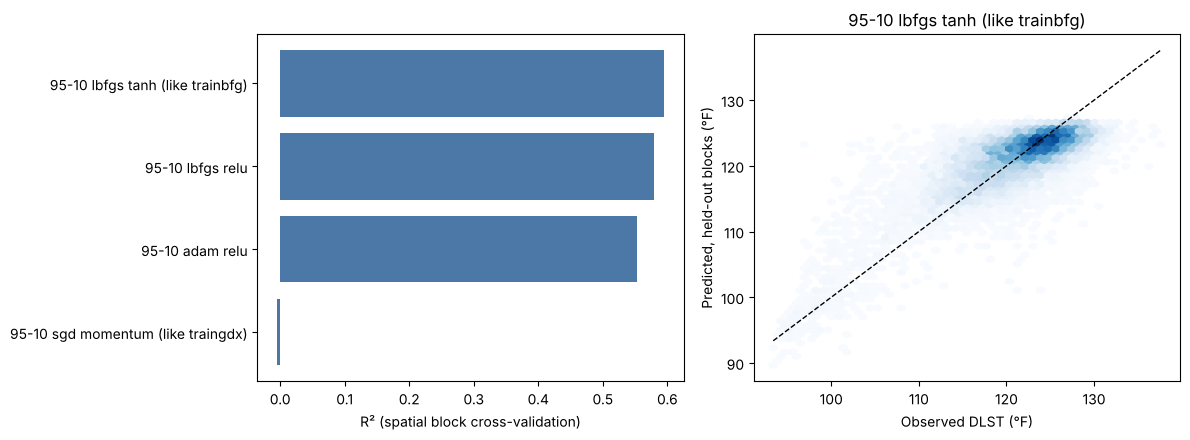

In [4]:
best_name = scores.model.iloc[0]
best = model.NETWORKS[best_name]
pred_cv = cross_val_predict(model.make_network(best), X, y, groups=groups, cv=GroupKFold(5))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].barh(scores.model, scores.r2, color="#4c78a8"); ax[0].invert_yaxis()
ax[0].set_xlabel("R² (spatial block cross-validation)")
ax[1].hexbin(y, pred_cv, gridsize=50, cmap="Blues", mincnt=1)
lims = [y.min(), y.max()]; ax[1].plot(lims, lims, "k--", lw=1)
ax[1].set_xlabel("Observed DLST (°F)"); ax[1].set_ylabel("Predicted, held-out blocks (°F)")
ax[1].set_title(best_name)
fig.tight_layout(); fig.savefig(FIG / "fig2_models.png", dpi=150, bbox_inches="tight")

In [5]:
sens, base_mse = model.drop_column_importance(best, X, y, groups)
sens.to_csv(OUT / "sensitivity_leave_one_out.csv", index=False)
print(f"MSE with all inputs: {base_mse:.3f}")
sens.round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


...

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


MSE with all inputs: 14.974


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


,left_out,mse,mse_increase
0,SR_Wh_m2,23.518,8.544
1,WBD_m,18.050,3.076
2,NDBI,17.223,2.249
3,NDVI,15.998,1.024
4,SVF,15.781,0.807
5,BRI_m2,15.781,0.807
6,BH_m,15.386,0.412
7,BVD,15.281,0.307


In [6]:
fitted = model.make_network(best).fit(X, y)
base = fitted.predict(X)

# DLST on the 10 m roof grid (each 30 m cell covers 3 x 3 roof pixels)
dlst10 = np.kron(y.to_numpy().reshape(shape), np.ones((3, 3)))
chosen = simulate.select_rooftops(roofs["roof_ids"], dlst10, target_share=0.042, heights=roofs["height"])
ndvi10, ndbi10 = simulate.green_roof_scenario(roofs["ndvi"], roofs["ndbi"], chosen)
Xg = X.copy()
Xg["NDVI"] = lidar.aggregate(ndvi10, 3).ravel()
Xg["NDBI"] = lidar.aggregate(ndbi10, 3).ravel()
green = fitted.predict(Xg)
delta = (green - base).reshape(shape)
summary = simulate.cooling_summary(base, green)
roof_share = chosen.sum() / (roofs["roof_ids"] > 0).sum()
summary["roof_share_converted"] = float(roof_share)
summary

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


{'cells_changed': 263,
 'mean_change': -2.7151856280452202,
 'min_change': -12.901462826079992,
 'max_change': 0.8034261102723832,
 'cells_cooler': 262,
 'cells_warmer': 1,
 'roof_share_converted': 0.0419655815882231}

In [7]:
d = df.assign(change=delta.ravel())
d = d[d.change.abs() > 0.02]
bins = {"BH_m": [0, 13, 28, 50, 400], "SVF": [0, 0.6, 0.7, 0.8, 1.01],
        "WBD_m": [0, 50, 100, 200, 1000]}
rows = []
for k, b in bins.items():
    g = d.groupby(pd.cut(d[k], b, right=False), observed=True).change
    for interval, s in g:
        rows.append({"variable": k, "class": str(interval), "cells": len(s), "mean_change_F": s.mean()})
by_class = pd.DataFrame(rows)
by_class.to_csv(OUT / "cooling_by_class.csv", index=False)
by_class.round(2)

,variable,class,cells,mean_change_F
0,BH_m,"[0, 13)",198,-2.40
1,BH_m,"[13, 28)",54,-3.40
2,BH_m,"[28, 50)",8,-4.97
3,BH_m,"[50, 400)",3,-5.25
4,SVF,"[0.0, 0.6)",30,-3.61
5,SVF,"[0.6, 0.7)",88,-2.09
6,SVF,"[0.7, 0.8)",110,-2.53
7,SVF,"[0.8, 1.01)",35,-4.08
8,WBD_m,"[0, 50)",200,-2.66
9,WBD_m,"[50, 100)",60,-2.99


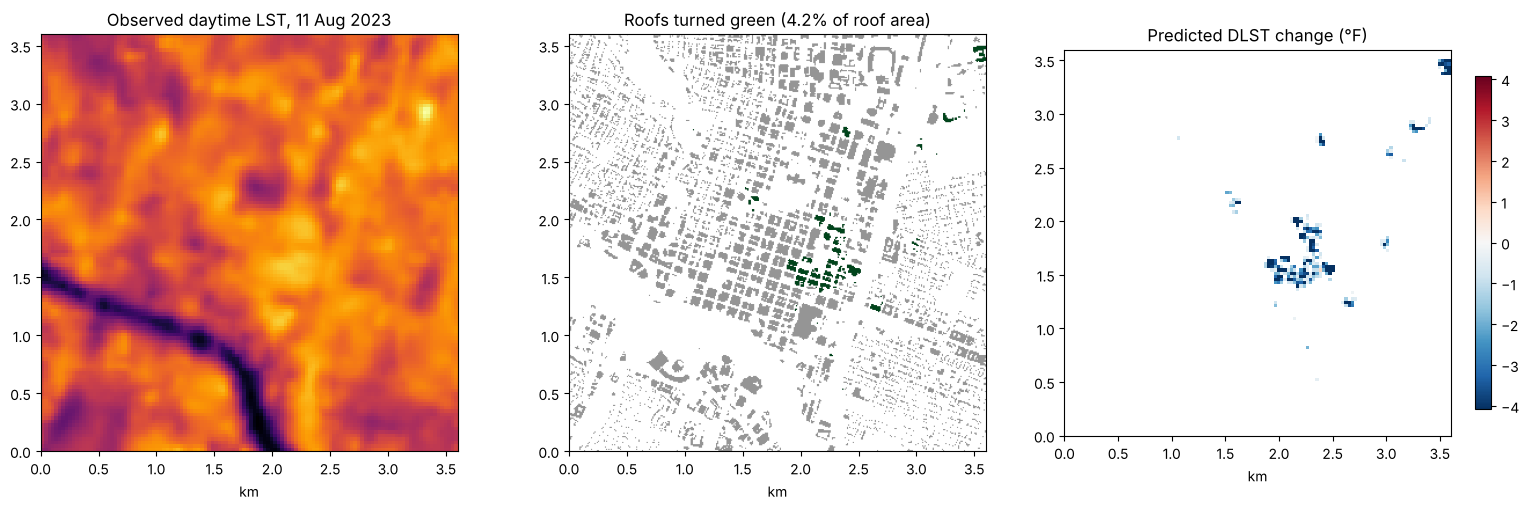

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(df.DLST_F.to_numpy().reshape(shape), cmap="inferno", extent=(0, 3.6, 0, 3.6))
ax[0].set_title("Observed daytime LST, 11 Aug 2023")
ax[1].imshow(np.ma.masked_where(roofs["roof_ids"] == 0, roofs["roof_ids"] > 0), cmap="Greys", vmin=0, vmax=2, extent=(0, 3.6, 0, 3.6))
ax[1].imshow(np.ma.masked_where(~chosen, chosen), cmap="Greens_r", extent=(0, 3.6, 0, 3.6))
ax[1].set_title(f"Roofs turned green ({100 * roof_share:.1f}% of roof area)")
lim = max(0.5, np.nanpercentile(np.abs(delta), 99.5))
im = ax[2].imshow(np.where(np.abs(delta) > 0.02, delta, np.nan), cmap="RdBu_r", vmin=-lim, vmax=lim, extent=(0, 3.6, 0, 3.6))
ax[2].set_title("Predicted DLST change (°F)")
fig.colorbar(im, ax=ax[2], shrink=0.8)
for a in ax: a.set_xlabel("km")
fig.tight_layout(); fig.savefig(FIG / "fig3_green_roofs.png", dpi=150, bbox_inches="tight")

In [9]:
out = {"best_network": best_name, "spatial_cv": scores.iloc[0][["r2", "rmse"]].round(3).to_dict(),
       "networks": scores.round(3).to_dict(orient="records"), "scenario": {k: (round(v, 3) if isinstance(v, float) else v) for k, v in summary.items()},
       "sensitivity_top3": sens.left_out.head(3).tolist()}
(OUT / "summary.json").write_text(json.dumps(out, indent=2))
out

{'best_network': '95-10 lbfgs tanh (like trainbfg)',
 'spatial_cv': {'r2': 0.595, 'rmse': 3.867},
 'networks': [{'model': '95-10 lbfgs tanh (like trainbfg)',
   'r2': 0.595,
   'rmse': 3.867},
  {'model': '95-10 lbfgs relu', 'r2': 0.58, 'rmse': 3.942},
  {'model': '95-10 adam relu', 'r2': 0.554, 'rmse': 4.069},
  {'model': '95-10 sgd momentum (like traingdx)',
   'r2': -0.005,
   'rmse': 6.142}],
 'scenario': {'cells_changed': 263,
  'mean_change': -2.715,
  'min_change': -12.901,
  'max_change': 0.803,
  'cells_cooler': 262,
  'cells_warmer': 1,
  'roof_share_converted': 0.042},
 'sensitivity_top3': ['SR_Wh_m2', 'WBD_m', 'NDBI']}